In [206]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
plt.style.use("ggplot")
plt.rcParams["figure.dpi"] = 100
font = {"family": "sans-serif", "size": 12}

mpl.rc("font", **font)

from IPython.display import Image


In [207]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import  train_test_split
from sklearn.metrics import accuracy_score, precision_score



In [169]:
df = pd.read_csv('customer_churn_data.csv')

In [170]:
df.shape

(7043, 21)

In [171]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [172]:
df.describe(include=['object'])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,3186-AJIEK,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [173]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [174]:
# Total Charges should have been neumeric; lets chcek this

df.TotalCharges.value_counts()
# First row is empty ; so convert to  NAN

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [175]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [176]:
df.dropna(inplace=True)

In [177]:
df.drop(columns='customerID', inplace=True, axis=1)

In [178]:
df.duplicated().sum()

np.int64(22)

In [179]:
df.drop_duplicates(inplace=True)

In [180]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')


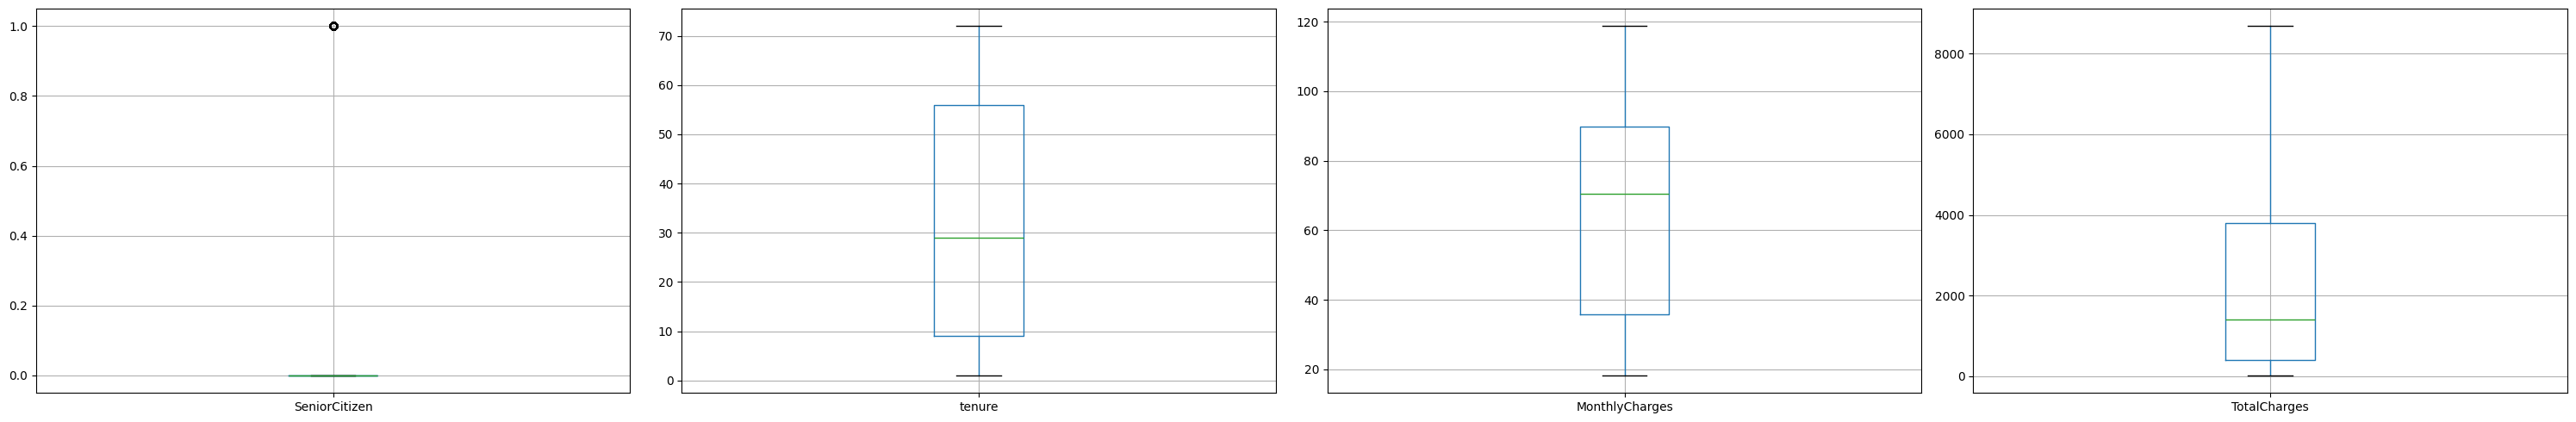

In [181]:
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
print(numeric_columns)
fig, axes = plt.subplots(1, len(numeric_columns), figsize=(30, 5))
for ax, col in zip(axes, numeric_columns):
    df.boxplot(column=col, ax=ax) 

plt.tight_layout()
plt.show()

In [182]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

object_columns = df.select_dtypes(include='object').columns.tolist()
object_columns

for col in object_columns:
    df[col] =le.fit_transform(df[col])
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 7010 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7010 non-null   int64  
 1   SeniorCitizen     7010 non-null   int64  
 2   Partner           7010 non-null   int64  
 3   Dependents        7010 non-null   int64  
 4   tenure            7010 non-null   int64  
 5   PhoneService      7010 non-null   int64  
 6   MultipleLines     7010 non-null   int64  
 7   InternetService   7010 non-null   int64  
 8   OnlineSecurity    7010 non-null   int64  
 9   OnlineBackup      7010 non-null   int64  
 10  DeviceProtection  7010 non-null   int64  
 11  TechSupport       7010 non-null   int64  
 12  StreamingTV       7010 non-null   int64  
 13  StreamingMovies   7010 non-null   int64  
 14  Contract          7010 non-null   int64  
 15  PaperlessBilling  7010 non-null   int64  
 16  PaymentMethod     7010 non-null   int64  
 17  

In [183]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,2,0,2,0,2,2,2,2,1,1,3,84.80,1990.50,0
7039,0,0,1,1,72,1,2,1,0,2,2,0,2,2,1,1,1,103.20,7362.90,0
7040,0,0,1,1,11,0,1,0,2,0,0,0,0,0,0,1,2,29.60,346.45,0
7041,1,1,1,0,4,1,2,1,0,0,0,0,0,0,0,1,3,74.40,306.60,1


In [184]:
X = df.drop(columns='Churn', axis=1)
y = df.Churn

In [185]:
display(y.value_counts())


Churn
0    5153
1    1857
Name: count, dtype: int64

In [186]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=42, stratify=y)

In [187]:
RF = RandomForestClassifier(
        # n_estimators=400,
        # max_depth=12,
        # min_samples_split=10,
        # min_samples_leaf=5,
        # max_features="sqrt",
        # class_weight="balanced_subsample",
        # random_state=42,
        # n_jobs=-1
    
)

In [188]:
y_train.value_counts()

Churn
0    4122
1    1486
Name: count, dtype: int64

In [189]:
RF.fit(X_train, y_train)

RandomForestClassifier()

In [190]:
y_pred = RF.predict(X_test)
y_pred_train = RF.predict(X_train)


In [191]:
print('Accuracy score of test in RF: ', np.round(accuracy_score(y_test, y_pred), 2))
print('Accuracy score of train RF: ',   np.round(accuracy_score(y_train, y_pred_train), 2))



Accuracy score of test in RF:  0.79
Accuracy score of train RF:  1.0


In [192]:
%%script false --no-raise-error
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 8))
plot_tree(
    RF.estimators_[0],
    feature_names=X.columns,
    filled=True,
    rounded=True,
)
plt.show()

In [193]:
#RandomForestClassifier

## Hyperparameter Optimization

In [194]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import random
params = {
    'n_estimators':[100, 200, 300, 400, 500, 700], # no of decision Trees
    'max_depth': [None, 5, 10, 15, 20, 30], # maximum depth of the tree. 
    #'criterion': ['gini', 'entropy', 'log_loss'] ,
    'min_samples_split':  [2, 5, 10, 15, 20], #minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4, 5, 8, 10],
    'class_weight': [None, 'balanced', 'balanced_subsample'],
    'bootstrap': [True, False],
    'max_features': ['sqrt', 'log2', None]
}

ind_parameters = {
    'criterion': 'gini'
    #'oob_score' :  True, # oob only availabel if bootstrapping is true
    #'class_weight': 'balanced'
}

# StratifiedKfold
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(** ind_parameters),
    param_distributions=params,
    n_iter=40,
    scoring='recall', # using recall since goal is to catch the churners
    cv=stratified_cv,
    refit=True,
    return_train_score=True,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [195]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=RandomForestClassifier(), n_iter=40, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'class_weight': [None, 'balanced',
                                                         'balanced_subsample'],
                                        'max_depth': [None, 5, 10, 15, 20, 30],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 2, 4, 5, 8, 10],
                                        'min_samples_split': [2, 5, 10, 15, 20],
                                        'n_estimators': [100, 200, 300, 400,
                                                         500, 700]},
                   random_state=42, return_train_score=True, scoring='recall',
                   verbose=1)

In [196]:
print("Best mean CV recall:")
random_search.best_score_

Best mean CV recall:


np.float64(0.8082005739723861)

In [197]:
random_search.best_params_

{'n_estimators': 300,
 'min_samples_split': 15,
 'min_samples_leaf': 5,
 'max_features': 'sqrt',
 'max_depth': 5,
 'class_weight': 'balanced_subsample',
 'bootstrap': False}

In [198]:
from sklearn.metrics import *
RF_best = random_search.best_estimator_

y_train_pred = RF_best.predict(X_train)
y_test_pred = RF_best.predict(X_test)

print("Train accuracy:",accuracy_score(y_train, y_train_pred))

print("Test accuracy:",accuracy_score(y_test, y_test_pred))

print("Test classification report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"],
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

y_test_prob = RF_best.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))


Train accuracy: 0.7532097004279601
Test accuracy: 0.7496433666191156
Test classification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81      1031
       Churn       0.52      0.78      0.62       371

    accuracy                           0.75      1402
   macro avg       0.71      0.76      0.72      1402
weighted avg       0.80      0.75      0.76      1402

Confusion matrix:
[[760 271]
 [ 80 291]]
Test ROC-AUC: 0.8426840714141924


 # Interpritation of results:

- Recall: What proportion of actual churners did the model identify?



- Precision: Of the customers predicted to churn, what proportion actually churned?



- F1-score: A balance between precision and recall.



- PR-AUC: Particularly useful for assessing churn detection when churners are the minority class.



- ROC-AUC: Measures how well the model ranks churners above non-churners across thresholds.

## Handeling Class Imbalance 

Churn
0    5153
1    1857
Name: count, dtype: int64

36.03725984863186

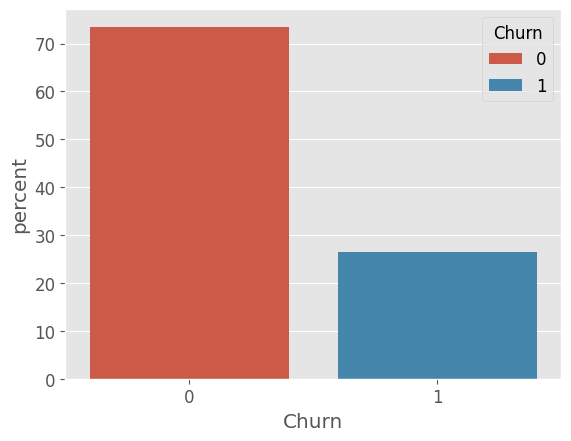

In [208]:
sns.countplot(df, x = 'Churn', stat='percent', hue='Churn')
display(y.value_counts())

(len(df.loc[df.Churn==1])) / (len(df.loc[df.Churn == 0])) * 100

There is a class imbalance. Firstly, try other algorithms and also different metric, like boosting and bagging both. Resampling Techniques:

1. **Under Sampling:** Select n samples at random from the majority class, where n is the number of samples for the minority class, and use them during the training phase, after excluding the sample to use for validation. But a drawback to undersampling is that we are removing information that may be valuable.

A better way to handle is to use `imbalanced-learn` lib

**Dropping by distance with NearMiss** : Chooses majority rows by how close they are to minority rows instead of at random. Version 1, the default, keeps the majority rows with the smallest average distance to their three nearest minority rows, so the survivors sit on the boundary. It takes no random_state, because nothing about it is random.

https://www.krishnaik.in/ai-tutorials/eda-and-feature-engineering/undersampling




In [200]:
df.shape

(7010, 20)

In [201]:
# separate minority and majority classes
not_churn = df[df.Churn==0]
churn = df[df.Churn==1]


In [202]:
from sklearn.utils import resample

not_churn_downsampled = resample(not_churn,
                                 replace=False,
                                 n_samples=len(churn),
                                 random_state=42
                                 )
downsampled = pd.concat([not_churn_downsampled, churn])
downsampled.Churn.value_counts()

## This was will loose the most info 

Churn
0    1857
1    1857
Name: count, dtype: int64

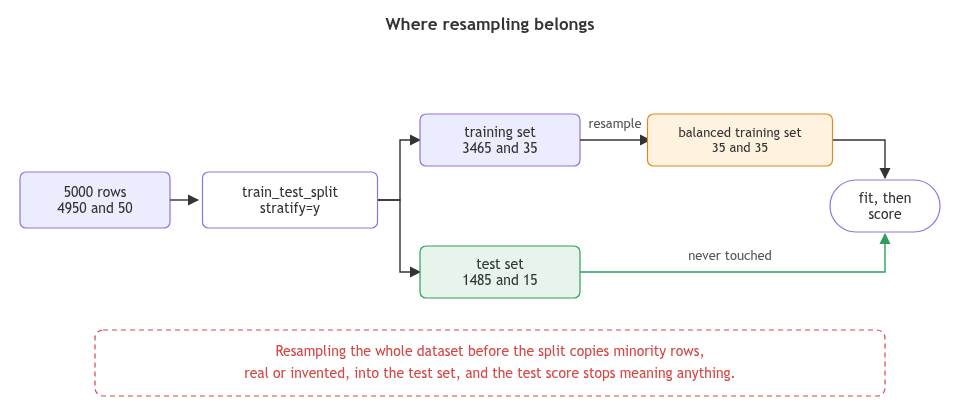

In [203]:
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter


# 1. Undersample ONLY the training data
under = RandomUnderSampler(
    sampling_strategy=0.7, #the minority-to-majority ratio after undersampling, 
                           #rather than forcing both classes to be exactly equal; try other values
    random_state=42
)

X_train_under, y_train_under = under.fit_resample(X_train, y_train)

print("Original training distribution:",
      Counter(y_train))

print("Undersampled training distribution:",
      Counter(y_train_under))

print("Untouched test distribution:",
      Counter(y_test))

# 2. Train Random Forest (using the bes RF here ; but there will not be class weights)

rf_under = RandomForestClassifier(
 n_estimators = 300,
 min_samples_split= 15,
 min_samples_leaf= 5,
 max_features= 'sqrt',
 max_depth = 5,
 class_weight = None, # since undersampling
 bootstrap =  False
)

rf_under.fit(X_train_under, y_train_under)

# 3. Evaluate on the original test set
y_pred = rf_under.predict(X_test)
y_prob = rf_under.predict_proba(X_test)[:, 1]

print("\nTest accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_prob))


Original training distribution: Counter({0: 4122, 1: 1486})
Undersampled training distribution: Counter({0: 2122, 1: 1486})
Untouched test distribution: Counter({0: 1031, 1: 371})

Test accuracy: 0.7781740370898717

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1031
           1       0.56      0.71      0.63       371

    accuracy                           0.78      1402
   macro avg       0.72      0.76      0.74      1402
weighted avg       0.80      0.78      0.79      1402

Confusion matrix:
[[827 204]
 [107 264]]
ROC-AUC: 0.8450605357894491
PR-AUC: 0.6420501978564215


In [212]:
from imblearn.under_sampling import NearMiss
from collections import Counter

rf_test = RandomForestClassifier(
 n_estimators = 300,
 min_samples_split= 15,
 min_samples_leaf= 5,
 max_features= 'sqrt',
 max_depth = 5,
 class_weight = None, # since undersampling
 bootstrap =  False
)


under = RandomUnderSampler(sampling_strategy="auto", random_state=42)
half = RandomUnderSampler(sampling_strategy=0.5, random_state=42)
near = NearMiss(version=1)

for name, sampler in [("none", None), 
                      ("RandomUnderSampler", under),
                      ("sampling_strategy=0.5", half), 
                      ("NearMiss v1", near)]:
    
    Xa, ya = (X_train, y_train) if sampler is None else sampler.fit_resample(X_train, y_train)

    p = rf_test.fit(Xa, ya).predict(X_test)
    
    print(f"{name:22s} rows {len(ya):5d}  accuracy {accuracy_score(y_test, p):.4f}"
          f"  precision {precision_score(y_test, p, zero_division=0):.3f}"
          f"  recall {recall_score(y_test, p):.3f}")

none                   rows  5608  accuracy 0.7882  precision 0.654  recall 0.423
RandomUnderSampler     rows  2972  accuracy 0.7504  precision 0.519  recall 0.790
sampling_strategy=0.5  rows  4458  accuracy 0.7946  precision 0.621  recall 0.574
NearMiss v1            rows  2972  accuracy 0.6241  precision 0.390  recall 0.741


In [213]:
## Just on the basis of catching the churn i.e Recall value; the RandomUnderSampler auto performs better. 

## Oversampling and SMOTE

Oversampling is balancing a training set by adding minority rows rather than removing majority ones: RandomOverSampler copies rows that exist, and SMOTE invents new ones between them.


**SMOTE** stands for Synthetic Minority Over-sampling Technique. Instead of copying a minority row, it picks one, looks at its `k_neighbors` nearest minority rows, chooses one of them at random and places a new row at a random point on the straight line between the two.

https://www.krishnaik.in/ai-tutorials/eda-and-feature-engineering/oversampling-and-smote

In [214]:
from imblearn.over_sampling import RandomOverSampler, SMOTE

over = RandomOverSampler(sampling_strategy="auto", random_state=42)
X_over, y_over = over.fit_resample(X_train, y_train)

smote = SMOTE(sampling_strategy="auto", random_state=42, k_neighbors=5)
X_smote, y_smote = smote.fit_resample(X_train, y_train)


half = SMOTE(sampling_strategy=0.5, random_state=42)


for name, data in [("none", (X_train, y_train)),
                   ("RandomOverSampler", (X_over, y_over)),
                   ("SMOTE", (X_smote, y_smote)),
                   ("SMOTE 0.5", half.fit_resample(X_train, y_train))]:
    Xa, ya = data
    p = rf_test.fit(Xa, ya).predict(X_test)
    print(f"{name:18s} rows {len(ya):5d}  accuracy {accuracy_score(y_test, p):.4f}"
          f"  precision {precision_score(y_test, p, zero_division=0):.3f}"
          f"  recall {recall_score(y_test, p):.3f}  f1 {f1_score(y_test, p, zero_division=0):.3f}")

none               rows  5608  accuracy 0.7882  precision 0.653  recall 0.426  f1 0.515
RandomOverSampler  rows  8244  accuracy 0.7482  precision 0.516  recall 0.792  f1 0.625
SMOTE              rows  8244  accuracy 0.7625  precision 0.537  recall 0.741  f1 0.623
SMOTE 0.5          rows  6183  accuracy 0.7874  precision 0.611  recall 0.542  f1 0.574
